<a href="https://colab.research.google.com/github/ShamGaneshan2008/.ipynb-files-/blob/main/OLLAMA_LAB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
%pip -q install requests pandas matplotlib

In [7]:
import os
import re
import json
import time
import math
from getpass import getpass
from pathlib import Path
from datetime import datetime, timezone
from urllib.parse import urlsplit

import requests
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

MODEL_NAME = "llama3.2:latest"
GENERATION_OPTIONS = {"temperature": 0, "num_predict": 160}
CONNECT_TIMEOUT_SECONDS = 20
READ_TIMEOUT_SECONDS = 240

print("OLLAMA LAB | Remote Ollama through HTTPS ngrok")

OLLAMA LAB | Remote Ollama through HTTPS ngrok


In [8]:
OLLAMA_NGROK_URL = input("Current ngrok HTTPS URL: ").strip().rstrip("/")
OLLAMA_BASIC_USERNAME = input("ngrok Basic Auth username [ollama]: ").strip() or "ollama"
OLLAMA_BASIC_PASSWORD = getpass("ngrok Basic Auth password: ")

parsed_url = urlsplit(OLLAMA_NGROK_URL)
if parsed_url.scheme != "https" or not parsed_url.hostname or parsed_url.username or parsed_url.password or parsed_url.query or parsed_url.fragment or parsed_url.path not in ("", "/"):
    raise ValueError("Enter only the current public ngrok HTTPS base URL, for example https://example.ngrok-free.app")
if not OLLAMA_BASIC_PASSWORD:
    raise ValueError("The ngrok Basic Auth password is required")

session = requests.Session()
session.auth = (OLLAMA_BASIC_USERNAME, OLLAMA_BASIC_PASSWORD)
session.headers.update({"Accept": "application/json", "ngrok-skip-browser-warning": "true"})
print("Secure endpoint configured:", OLLAMA_NGROK_URL)
print("Model:", MODEL_NAME)
print("Basic Auth: configured; password not displayed")


Current ngrok HTTPS URL: https://resonate-submersed-perkiness.ngrok-free.dev
ngrok Basic Auth username [ollama]: ollama
ngrok Basic Auth password: ··········
Secure endpoint configured: https://resonate-submersed-perkiness.ngrok-free.dev
Model: llama3.2:latest
Basic Auth: configured; password not displayed


In [9]:
def ollama_request(method, path, payload=None):
    try:
        response = session.request(
            method,
            f"{OLLAMA_NGROK_URL}{path}",
            json=payload,
            timeout=(CONNECT_TIMEOUT_SECONDS, READ_TIMEOUT_SECONDS),
            allow_redirects=False,
        )
    except requests.exceptions.Timeout as exc:
        raise RuntimeError("Request timed out. Check that the laptop is awake and Ollama is responding") from exc
    except requests.exceptions.SSLError as exc:
        raise RuntimeError("HTTPS certificate verification failed. Do not disable TLS verification") from exc
    except requests.exceptions.ConnectionError as exc:
        raise RuntimeError("Cannot reach the current ngrok URL. Check the active tunnel and network connection") from exc
    except requests.exceptions.RequestException as exc:
        raise RuntimeError(f"Network request failed: {type(exc).__name__}") from exc

    if response.status_code in (301, 302, 303, 307, 308):
        raise RuntimeError("Unexpected redirect. Enter the ngrok HTTPS base URL shown by the active agent")
    if response.status_code == 401:
        raise RuntimeError("HTTP 401: ngrok Basic Auth rejected the username or password")
    if response.status_code == 403:
        raise RuntimeError("HTTP 403: ngrok denied access. Check the active endpoint's traffic policy and ngrok Inspector")
    if response.status_code in (502, 503, 504):
        raise RuntimeError(f"HTTP {response.status_code}: ngrok is reachable but cannot get a valid response from local Ollama")
    if not response.ok:
        raise RuntimeError(f"HTTP {response.status_code} from the tunnel or Ollama; inspect the matching ngrok request")

    content_type = response.headers.get("Content-Type", "").lower()
    if "json" not in content_type:
        raise RuntimeError("Endpoint returned non-JSON content. Confirm ngrok forwards to http://localhost:11434")
    try:
        data = response.json()
    except ValueError as exc:
        raise RuntimeError("Endpoint returned invalid JSON") from exc
    if not isinstance(data, dict):
        raise RuntimeError("Unexpected JSON response: expected an object")
    if data.get("error"):
        raise RuntimeError(f"Ollama API returned an error: {str(data['error'])[:300]}")
    return data


In [10]:
tags_data = ollama_request("GET", "/api/tags")
available_models = [item.get("name", "") for item in tags_data.get("models", []) if isinstance(item, dict)]
print("Available models:", available_models)
if MODEL_NAME not in available_models:
    raise RuntimeError(f"'{MODEL_NAME}' is unavailable. On Windows run: ollama pull {MODEL_NAME}")
print("HTTPS connection, authentication, and model check succeeded")

Available models: ['llama3.2:latest']
HTTPS connection, authentication, and model check succeeded


In [11]:
test_cases = [
    {
        "id": "A01",
        "category": "Arithmetic",
        "question": "A company has 100 products. It sells 30 products and purchases 20 more. How many products does it have now? Explain the calculation.",
        "accepted_answers": ["90"]
    },
    {
        "id": "A02",
        "category": "Arithmetic",
        "question": "What is 25 multiplied by 16? Give the numerical answer.",
        "accepted_answers": ["400"]
    },
    {
        "id": "A03",
        "category": "Arithmetic",
        "question": "A shop has 48 notebooks and packs them equally into 6 boxes. How many notebooks go in each box?",
        "accepted_answers": ["8"]
    },
    {
        "id": "L01",
        "category": "Logic",
        "question": "All roses are flowers. Some flowers fade quickly. Does it logically follow that all roses fade quickly? Answer yes or no and explain.",
        "accepted_answers": ["no"]
    },
    {
        "id": "L02",
        "category": "Logic",
        "question": "A is taller than B. B is taller than C. Who is the shortest: A, B, or C?",
        "accepted_answers": ["c"]
    },
    {
        "id": "P01",
        "category": "Pattern",
        "question": "Find the next number in this sequence: 2, 4, 8, 16, 32.",
        "accepted_answers": ["64"]
    },
    {
        "id": "P02",
        "category": "Pattern",
        "question": "Find the next number in this sequence: 3, 6, 9, 12.",
        "accepted_answers": ["15"]
    },
    {
        "id": "C01",
        "category": "Programming",
        "question": "In Python, what does len([10, 20, 30, 40]) return? Give the result.",
        "accepted_answers": ["4"]
    },
    {
        "id": "C02",
        "category": "Programming",
        "question": "In Python, what is the output of print(3 ** 2)? Give only the output.",
        "accepted_answers": ["9"]
    },
    {
        "id": "G01",
        "category": "General Knowledge",
        "question": "Which planet is commonly called the Red Planet?",
        "accepted_answers": ["mars"]
    },
    {
        "id": "G02",
        "category": "General Knowledge",
        "question": "What is the chemical symbol for water?",
        "accepted_answers": ["h2o"]
    },
    {
        "id": "G03",
        "category": "General Knowledge",
        "question": "How many sides does a hexagon have?",
        "accepted_answers": ["6", "six"]
    }
]

dataset_df = pd.DataFrame(test_cases)
display(dataset_df[["id", "category", "question"]])
print("Questions:", len(test_cases))

,id,category,question
0,A01,Arithmetic,A company has 100 products. It sells 30 produc...
1,A02,Arithmetic,What is 25 multiplied by 16? Give the numerica...
2,A03,Arithmetic,A shop has 48 notebooks and packs them equally...
3,L01,Logic,All roses are flowers. Some flowers fade quick...
4,L02,Logic,A is taller than B. B is taller than C. Who is...
5,P01,Pattern,"Find the next number in this sequence: 2, 4, 8..."
6,P02,Pattern,"Find the next number in this sequence: 3, 6, 9..."
7,C01,Programming,"In Python, what does len([10, 20, 30, 40]) ret..."
8,C02,Programming,"In Python, what is the output of print(3 ** 2)..."
9,G01,General Knowledge,Which planet is commonly called the Red Planet?


Questions: 12


In [12]:
def ask_ollama(prompt, model=MODEL_NAME, options=None):
    if not isinstance(prompt, str) or not prompt.strip():
        raise ValueError("Prompt must be a non-empty string")
    payload = {
        "model": model,
        "messages": [{"role": "user", "content": prompt.strip()}],
        "stream": False,
        "options": GENERATION_OPTIONS if options is None else options,
    }
    started = time.perf_counter()
    data = ollama_request("POST", "/api/chat", payload)
    elapsed_seconds = time.perf_counter() - started
    message = data.get("message")
    if not isinstance(message, dict) or not isinstance(message.get("content"), str):
        raise RuntimeError("Ollama chat response is missing message.content")

    def duration_in_seconds(key):
        value = data.get(key)
        return round(value / 1e9, 3) if isinstance(value, (int, float)) else None

    return {
        "answer": message["content"],
        "elapsed_seconds": round(elapsed_seconds, 3),
        "total_duration_seconds": duration_in_seconds("total_duration"),
        "prompt_tokens": data.get("prompt_eval_count"),
        "generated_tokens": data.get("eval_count"),
        "generation_duration_seconds": duration_in_seconds("eval_duration"),
    }

smoke_test = ask_ollama("Reply with exactly: OLLAMA CONNECTION SUCCESSFUL")
print("Smoke test:", smoke_test["answer"])
print("Latency (seconds):", smoke_test["elapsed_seconds"])


Smoke test: OLLAMA CONNECTION SUCCESSFUL
Latency (seconds): 6.415


In [13]:
experiment_rows = []
for index, item in enumerate(test_cases, 1):
    print(f"[{index}/{len(test_cases)}] {item['id']} ({item['category']})")
    row = {
        "id": item["id"], "category": item["category"],
        "question": item["question"], "accepted_answers": item["accepted_answers"],
        "response": "", "elapsed_seconds": None, "total_duration_seconds": None,
        "prompt_tokens": None, "generated_tokens": None,
        "generation_duration_seconds": None, "error": None,
    }
    try:
        result = ask_ollama(item["question"])
        row.update({key: result[key] for key in ("elapsed_seconds", "total_duration_seconds", "prompt_tokens", "generated_tokens", "generation_duration_seconds")})
        row["response"] = result["answer"]
        print("Response:", result["answer"][:180].replace("\n", " "))
    except Exception as exc:
        row["error"] = str(exc)
        print("Error:", row["error"])
    experiment_rows.append(row)
results_df = pd.DataFrame(experiment_rows)
print("Experiment complete:", len(results_df), "attempted")

[1/12] A01 (Arithmetic)
Response: To find the total number of products the company has now, we need to add the number of products it had initially (100) to the number of products it purchased (20).  However, we als
[2/12] A02 (Arithmetic)
Response: 25 × 16 = 400
[3/12] A03 (Arithmetic)
Response: To find out how many notebooks go in each box, we need to divide the total number of notebooks (48) by the number of boxes (6).  48 ÷ 6 = 8  So, 8 notebooks go in each box.
[4/12] L01 (Logic)
Response: No, it does not logically follow that all roses fade quickly.  The statement "All roses are flowers" is a universal affirmative statement, which means it applies to every member of
[5/12] L02 (Logic)
Response: Based on the information provided, we can deduce the following:  1. A is taller than B. 2. B is taller than C.  From these two statements, we can conclude that A is the tallest, B 
[6/12] P01 (Pattern)
Response: The pattern of the sequence is obtained by multiplying the previous term by 2. 

In [14]:
def normalize_text(value):
    return re.sub(r"\s+", " ", str(value).lower()).strip()

def keyword_screen(response, accepted_answers):
    if not response:
        return False
    normalized = normalize_text(response)
    for accepted in accepted_answers:
        candidate = normalize_text(accepted)
        pattern = r"(?<![a-z0-9])" + re.escape(candidate) + r"(?![a-z0-9])"
        if re.search(pattern, normalized):
            return True
    return False

results_df["screen_pass"] = results_df.apply(
    lambda row: keyword_screen(row["response"], row["accepted_answers"]) if not row["error"] else False,
    axis=1,
)
results_df["status"] = results_df["error"].apply(lambda error: "ERROR" if error else "COMPLETED")
display(results_df[["id", "category", "screen_pass", "elapsed_seconds", "status"]])

,id,category,screen_pass,elapsed_seconds,status
0,A01,Arithmetic,True,17.011,COMPLETED
1,A02,Arithmetic,True,1.265,COMPLETED
2,A03,Arithmetic,True,5.735,COMPLETED
3,L01,Logic,True,17.055,COMPLETED
4,L02,Logic,True,7.085,COMPLETED
5,P01,Pattern,True,7.554,COMPLETED
6,P02,Pattern,True,6.770,COMPLETED
7,C01,Programming,True,5.135,COMPLETED
8,C02,Programming,True,0.680,COMPLETED
9,G01,General Knowledge,True,4.450,COMPLETED


In [15]:
completed_df = results_df[results_df["status"] == "COMPLETED"].copy()
total_questions = len(results_df)
completed_count = len(completed_df)
passed_count = int(completed_df["screen_pass"].sum())
screening_rate = 100 * passed_count / completed_count if completed_count else 0.0
average_latency = float(completed_df["elapsed_seconds"].mean()) if completed_count else None
print(f"Model: {MODEL_NAME}")
print(f"Completed: {completed_count}/{total_questions} | Errors: {total_questions - completed_count}")
print(f"Keyword-screen passes: {passed_count} | Rate (completed only): {screening_rate:.2f}%")
print(f"Mean latency: {average_latency:.3f}s" if average_latency is not None else "Mean latency: N/A")
print("This keyword screening is NOT a validated reasoning accuracy measurement")

Model: llama3.2:latest
Completed: 12/12 | Errors: 0
Keyword-screen passes: 12 | Rate (completed only): 100.00%
Mean latency: 6.730s
This keyword screening is NOT a validated reasoning accuracy measurement


,category,questions,screening_passes,average_latency_seconds,screening_pass_rate_percent
0,Arithmetic,3,3,8.00,100.0
1,General Knowledge,3,3,4.16,100.0
2,Logic,2,2,12.07,100.0
3,Pattern,2,2,7.16,100.0
4,Programming,2,2,2.91,100.0


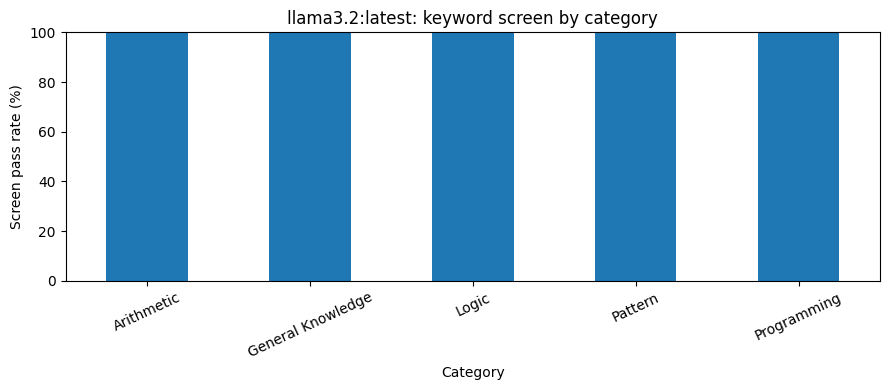

In [16]:
if completed_count:
    category_summary = completed_df.groupby("category", as_index=False).agg(
        questions=("id", "count"), screening_passes=("screen_pass", "sum"),
        average_latency_seconds=("elapsed_seconds", "mean"),
    )
    category_summary["screening_pass_rate_percent"] = (
        category_summary["screening_passes"] / category_summary["questions"] * 100
    )
    display(category_summary.round(2))
    ax = category_summary.plot.bar(
        x="category", y="screening_pass_rate_percent", legend=False,
        title=f"{MODEL_NAME}: keyword screen by category", figsize=(9, 4), rot=25,
    )
    ax.set_ylabel("Screen pass rate (%)")
    ax.set_xlabel("Category")
    ax.set_ylim(0, 100)
    plt.tight_layout()
    plt.show()
else:
    category_summary = pd.DataFrame()
    print("No completed responses to visualize")

In [17]:
for _, row in results_df.iterrows():
    print(f"{row['id']} | {row['category']} | {row['status']} | Keyword pass: {row['screen_pass']}")
    print("Question:", row["question"])
    print("Expected:", row["accepted_answers"])
    print("Generated:", row["response"] or "[empty]")
    if row["error"]:
        print("Error:", row["error"])
    print("-" * 60)

A01 | Arithmetic | COMPLETED | Keyword pass: True
Question: A company has 100 products. It sells 30 products and purchases 20 more. How many products does it have now? Explain the calculation.
Expected: ['90']
Generated: To find the total number of products the company has now, we need to add the number of products it had initially (100) to the number of products it purchased (20).

However, we also need to subtract the number of products it sold (30) from the initial number of products (100) to find the number of products it had left after selling.

Here's the step-by-step calculation:

1. Initial number of products: 100
2. Number of products sold: 30
3. Number of products left after selling: 100 - 30 = 70
4. Number of products purchased: 20
5. Total number of products now: 70 + 20 = 90

So, the company now has 90 products.
------------------------------------------------------------
A02 | Arithmetic | COMPLETED | Keyword pass: True
Question: What is 25 multiplied by 16? Give the nume

In [18]:
consistency_prompts = [
    "A store starts with 100 items, sells 30, then receives 20 new items. How many items remain?",
    "Calculate the final inventory: opening stock 100, sales 30, new purchases 20.",
    "Start at 100 products. Subtract 30 sold products and add 20 purchased products. What is the final count?",
]
consistency_rows = []
for i, prompt in enumerate(consistency_prompts, 1):
    row = {"prompt_version": i, "prompt": prompt, "response": "", "elapsed_seconds": None, "error": None}
    try:
        result = ask_ollama(prompt)
        row["response"] = result["answer"]
        row["elapsed_seconds"] = result["elapsed_seconds"]
    except Exception as exc:
        row["error"] = str(exc)
    consistency_rows.append(row)
consistency_df = pd.DataFrame(consistency_rows)
display(consistency_df)

,prompt_version,prompt,response,elapsed_seconds,error
0,1,"A store starts with 100 items, sells 30, then ...","To find the number of items remaining, we need...",9.618,None
1,2,Calculate the final inventory: opening stock 1...,"To calculate the final inventory, we need to s...",9.270,None
2,3,Start at 100 products. Subtract 30 sold produc...,"To find the final count, we need to perform th...",10.791,None


In [19]:
output_dir = Path("ollama_lab_results")
output_dir.mkdir(parents=True, exist_ok=True)
timestamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_UTC")
results_csv = output_dir / f"baseline_results_{timestamp}.csv"
consistency_csv = output_dir / f"consistency_results_{timestamp}.csv"
summary_json = output_dir / f"summary_{timestamp}.json"
results_df.to_csv(results_csv, index=False)
consistency_df.to_csv(consistency_csv, index=False)
summary = {
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "model": MODEL_NAME,
    "total_questions": total_questions,
    "completed_questions": completed_count,
    "error_count": total_questions - completed_count,
    "keyword_screen_passes": passed_count,
    "keyword_screen_pass_rate_percent": round(screening_rate, 2),
    "average_latency_seconds": round(average_latency, 3) if average_latency is not None else None,
    "consistency_prompt_count": len(consistency_df),
    "metric_warning": "Keyword screening is a heuristic, not validated reasoning accuracy",
}
summary_json.write_text(json.dumps(summary, indent=2), encoding="utf-8")
for path in (results_csv, consistency_csv, summary_json):
    print("Saved:", path.resolve())

Saved: /content/ollama_lab_results/baseline_results_20261107_120904_UTC.csv
Saved: /content/ollama_lab_results/consistency_results_20261107_120904_UTC.csv
Saved: /content/ollama_lab_results/summary_20261107_120904_UTC.json


In [20]:
print("TROUBLESHOOTING")
print("401: Re-enter the ngrok Basic Auth username and the newly rotated password")
print("403: Inspect the active ngrok endpoint's traffic policy and matching Inspector request")
print("502/503/504: Ensure Windows Ollama is running and ngrok forwards to port 11434")
print("404: Enter only the HTTPS ngrok base URL; the notebook adds /api/tags and /api/chat")
print("Timeout: Check laptop sleep, Ollama model load, and ngrok tunnel health")
print("HTML/non-JSON: Check the tunnel target and any ngrok interstitial page")
print("Windows checks: ollama list; curl.exe -i http://localhost:11434/api/tags")
print("Start ngrok separately with Basic Auth enabled; never put its password in this notebook")


TROUBLESHOOTING
401: Re-enter the ngrok Basic Auth username and the newly rotated password
403: Inspect the active ngrok endpoint's traffic policy and matching Inspector request
502/503/504: Ensure Windows Ollama is running and ngrok forwards to port 11434
404: Enter only the HTTPS ngrok base URL; the notebook adds /api/tags and /api/chat
Timeout: Check laptop sleep, Ollama model load, and ngrok tunnel health
HTML/non-JSON: Check the tunnel target and any ngrok interstitial page
Windows checks: ollama list; curl.exe -i http://localhost:11434/api/tags
Start ngrok separately with Basic Auth enabled; never put its password in this notebook
